# ДЗ 1
Галимов Данил Ильдарович

Использую [Amazon Reviews 2023, Musical Instruments](https://amazon-reviews-2023.github.io/). Рекомендую товары, на которые пользователь еще не оставил отзыв, положительными считаю оценки 4 и 5

Для запуска нужно установить `requirements.txt` и выполнить ячейки по порядку. Данные скачиваются автоматически. `RETRAIN = True` запускает обучение заново, иначе загружаются результаты из `results/`. Для запуска использовал Python 3.9.6:

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
python scripts/run_notebook.py

In [1]:
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dataset import prepare
from train import run, settings

random.seed(42)
np.random.seed(42)
RETRAIN = False
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_colwidth', 100)


Из отзывов беру `user_id`, `parent_asin`, `rating` и `timestamp`, время перевожу из миллисекунд в секунды, варианты одного товара объединяются по `parent_asin`

Убираю некорректные оценки и повторные пары, оставляя первый отзывб сначала делю данные по времени на 75/10/15. По train выбираю 4 000 популярных товаров и до 40 000 активных пользователей с минимум тремя отзывами на них, При равных частотах сортирую ID, так матрицы помещаются в память


In [2]:
raw, selected, train, validation, test, metadata, info = prepare()
shape = (info['users'], info['items'])
display(pd.Series({key: info[key] for key in ['raw_rows', 'invalid_rows', 'duplicate_pairs', 'clean_rows', 'rows', 'users', 'items', 'sparsity']}, name='Значение').to_frame())
display(pd.Series(info['missing'], name='Пропуски').to_frame())

,Значение
raw_rows,3.017439e+06
invalid_rows,0.000000e+00
duplicate_pairs,4.188800e+04
clean_rows,2.975551e+06
rows,2.285500e+05
users,4.000000e+04
items,4.000000e+03
sparsity,9.985716e-01


,Пропуски
user_id,0
item_id,0
rating,0
timestamp,0



Смотрю оценки, активность пользователей и популярность объектов, затем проверяю даты и метаданые

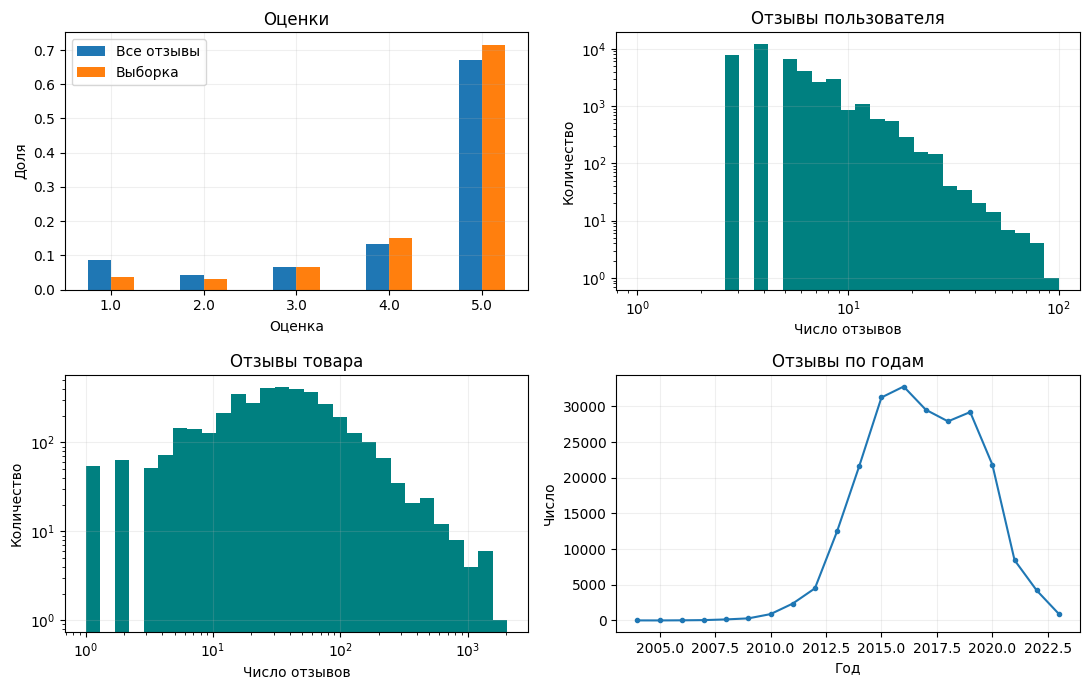

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
pd.concat([raw.rating.value_counts(normalize=True).rename('Все отзывы'), selected.rating.value_counts(normalize=True).rename('Выборка')], axis=1).sort_index().plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title='Оценки', xlabel='Оценка', ylabel='Доля')
for ax, column, label in [(axes[0, 1], 'user', 'Отзывы пользователя'), (axes[1, 0], 'item', 'Отзывы товара')]:
    counts = selected.groupby(column).size()
    ax.hist(counts, bins=np.geomspace(1, counts.max()+1, 30), color='teal')
    ax.set(xscale='log', yscale='log', title=label, xlabel='Число отзывов', ylabel='Количество')
pd.to_datetime(selected.timestamp, unit='s', utc=True).dt.year.value_counts().sort_index().plot(ax=axes[1, 1], marker='.')
axes[1, 1].set(title='Отзывы по годам', xlabel='Год', ylabel='Число')
plt.tight_layout()
plt.show()

,Заполненность
title,1.00000
categories,0.98025
store,0.99900


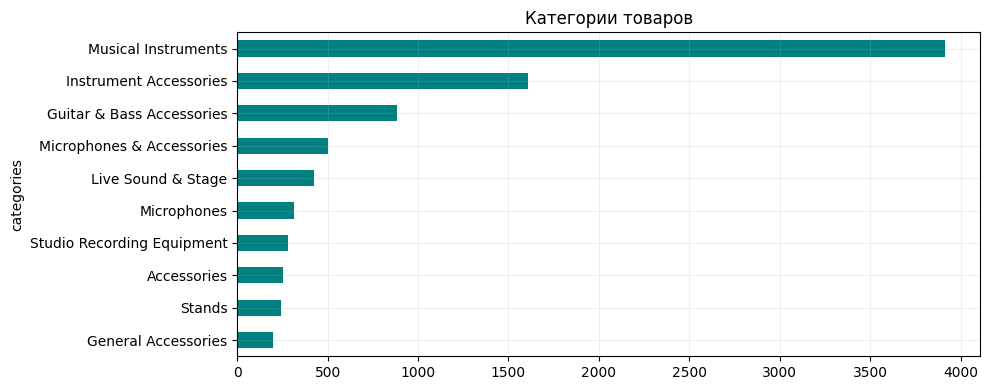

,title,store
item_id,,
0470536454,Crocheting for Dummies,For Dummies
0634003224,Essential Elements for Band - Trombone Book 1 with EEi,Hal Leonard Corp. (Author)
0689874162,Jingle Bugs (David Carter's Bugs),"David A. Carter (Author, Illustrator)"
0739079891,"Alfred’s Teach Yourself to Play Ukulele, Complete Starter Pack",Alfred Music
0793533929,Hal Leonard Guitar Method Book 1: Bk/Online Audio,"Will Schmid (Author), Greg Koch (Author)"


In [4]:
coverage = metadata.apply(lambda column: column.map(lambda value: isinstance(value, (str, list)) and len(value) > 0).mean())
display(coverage.rename('Заполненность').to_frame())
metadata.categories.dropna().explode().value_counts().head(10).sort_values().plot.barh(color='teal', title='Категории товаров')
plt.tight_layout()
plt.show()
display(metadata[['title', 'store']].head())


Одинаковые временные метки не разделяю, каталог и пользователи фикмируются по train, в каждом периоде беру общий набор пользователей с доступными положительными отзывами, yовые пользователи и объекты не участвуют в сравнении

Ранжирую весь каталог и убираю все ранее оцененные объекты, включая низкие оценки, история внутри периода не обновляется, при равных предсказаниях сортирую ID

Основная метрика NDCG@10 учитывает порядок списка, Recall@10 показывает долю найденных положительных объектовб обе считаю в среднем по пользователям, после подбора обучаю модели на train + validation и оцениваю на test.

In [5]:
print('Границы периодов:', pd.to_datetime(info['cutoffs'], unit='s', utc=True).strftime('%Y-%m-%d').tolist())
display(pd.DataFrame([{'period': name, 'rows': len(frame), 'users': frame.user.nunique(), 'items': frame.item.nunique()}
                      for name, frame in [('train', train), ('validation', validation), ('test', test)]]))
display(pd.DataFrame(info['excluded']))

Границы периодов: ['2021-02-17', '2021-12-09']


,period,rows,users,items
0,train,217651,40000,3961
1,validation,5522,3573,1756
2,test,5377,3356,1654


,period,before_filter,retained,new_users,new_items
0,validation,297556,5522,172195,16949
1,test,446333,5377,255412,33943


$$NDCG_u@10=\frac{\sum_{j=1}^{10}\mathbb{1}[i_j\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)},\qquad Recall_u@10=\frac{|L_u^{10}\cap R_u|}{|R_u|}.$$

-----------------------
Положительные отзывы записываю в бинарную матрицу $X$. Код лежит в `models/`

ItemKNN использует сглаженную меру Жаккара, где $n_i$ означает число положительных отзывов, а $n_{ij}$ число общих пользователей:
$$s_{ij}=\frac{n_{ij}}{n_i+n_j-n_{ij}+10},\quad s_{ii}=0,\qquad \hat y_{ui}=\sum_j X_{uj}s_{ji}$$
Для каждого товара оставляю $k$ соседей

ALS по очереди обновляет факторы пользователей и товаров:
$$\min_{A,B}\sum_{u,i}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2)$$
$p_{ui}=1$ при оценке 4 или 5. Для известных пар $c_{ui}=16$, для остальных 1

PersonalALS использует ту же задачу и confidence но другой таргет:
$$t_{ui}=\mathbb{1}[r_{ui}\ge4]\,\operatorname{clip}\left(1+\frac{r_{ui}-\bar r_u}{4},0.5,1.5\right)$$
$\bar r_u$ считается по обучающим отзывам. Проверяю, помогает ли учитывать привычный уровень оценок пользователя вместо одинакового отклика на все положительные отзывы.

EASE обучает линейную модель:
$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad W_{ii}=0.$$
При $P=(X^TX+\lambda I)^{-1}$ коэффициенты $W_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$, предсказания $XW$

FM использует ID и по три признака пользователя и товара: логарифм числа отзывов, среднюю оценку / 5 и стандартное отклонение оценок / 2, эти признаки описывают активность и разброс оценок
$$\hat y(x)=w_0+\sum_jw_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k$$
Исторические признаки считаются строго до времени примера, при пустой истории равны нулю, на каждый отзыв добавляю один случайный еще не оцененный товар с меткой 0, обучаю с BCE и Adam шаг 0,002 batch 4096

---------------------------------------
Использую seed 42, Сетки приведены ниже, выбор идет по NDCG@10 на validation, для ALS беру 12 итераций для FM до 12 эпох с остановкой после трех эпох без улучшения

После выбора повторяю сравнение двух ALS с одинаковыми параметрами и FM без дополнительных признаков. Эти настройки фиксируются до оценки test, для FM на train + validation использую лучшую эпоху с validation

In [6]:
display(pd.DataFrame([{'model': name, 'parameters': parameters} for name, parameters in settings()]))
path = Path('results/report.json')
report = run() if RETRAIN or not path.exists() else json.loads(path.read_text())
print('Пользователи validation:', report['validation_users'], 'test:', report['test_users'])
search = pd.DataFrame([{k: v for k, v in row.items() if k != 'history'} for row in report['search']])
display(search.sort_values(['model', 'NDCG@10'], ascending=[True, False]))

,model,parameters
0,ItemKNN,{'neighbors': 40}
1,ItemKNN,{'neighbors': 80}
2,ItemKNN,{'neighbors': 160}
3,EASE,{'penalty': 30}
4,EASE,{'penalty': 150}
5,EASE,{'penalty': 700}
6,ALS,"{'rank': 24, 'penalty': 0.3}"
7,ALS,"{'rank': 24, 'penalty': 3.0}"
8,ALS,"{'rank': 48, 'penalty': 0.3}"
9,ALS,"{'rank': 48, 'penalty': 3.0}"


Пользователи validation: 3055 test: 2835


,model,parameters,seconds,NDCG@10,Recall@10,best_epoch
7,ALS,"{'rank': 24, 'penalty': 3.0}",12.449439,0.024477,0.042200,NaN
6,ALS,"{'rank': 24, 'penalty': 0.3}",12.463000,0.024256,0.041681,NaN
9,ALS,"{'rank': 48, 'penalty': 3.0}",19.340928,0.022084,0.039560,NaN
8,ALS,"{'rank': 48, 'penalty': 0.3}",20.573136,0.021989,0.039560,NaN
5,EASE,{'penalty': 700},3.992690,0.029408,0.047148,NaN
4,EASE,{'penalty': 150},3.996430,0.028830,0.046714,NaN
3,EASE,{'penalty': 30},3.749670,0.026426,0.042099,NaN
16,FM,"{'factors': 24, 'reg': 1e-05}",15.599363,0.024200,0.040198,11.0
15,FM,"{'factors': 12, 'reg': 0.0001}",9.175556,0.023041,0.036851,5.0
17,FM,"{'factors': 24, 'reg': 0.0001}",7.799717,0.022805,0.035057,3.0


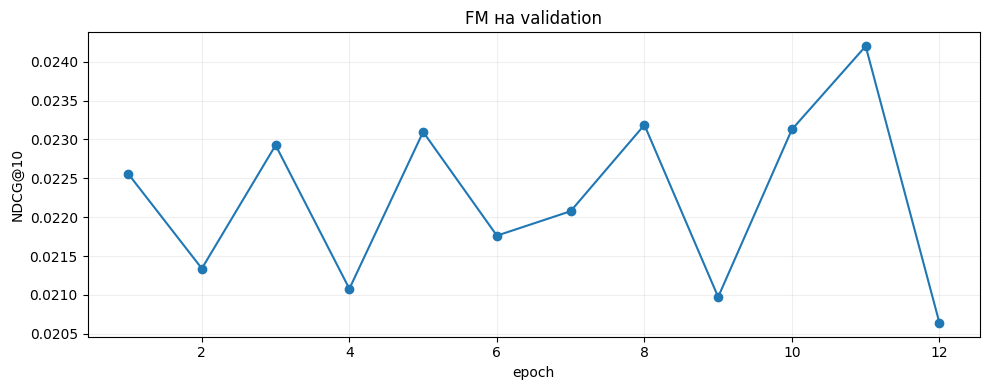

In [7]:
curve = max([row for row in report['search'] if row['model'] == 'FM'], key=lambda row: row['NDCG@10'])
pd.DataFrame(curve['history']).plot(x='epoch', y='ndcg', marker='o', legend=False, title='FM на validation')
plt.ylabel('NDCG@10')
plt.tight_layout()
plt.show()

---------------------
В таблице метрики на test, параметры и время обучения в секундах, для FM время первого запуска включает подготовку признаков

,parameters,seconds,NDCG@10,Recall@10
model,,,,
EASE,{'penalty': 700},3.679883,0.030015,0.051413
PersonalALS,"{'rank': 24, 'penalty': 3.0}",11.693212,0.025471,0.044554
ALS,"{'rank': 24, 'penalty': 3.0}",11.420151,0.025336,0.043015
ItemKNN,{'neighbors': 160},0.571971,0.021276,0.038173
FM,"{'factors': 24, 'reg': 1e-05, 'epochs': 11}",10.048488,0.019839,0.035436


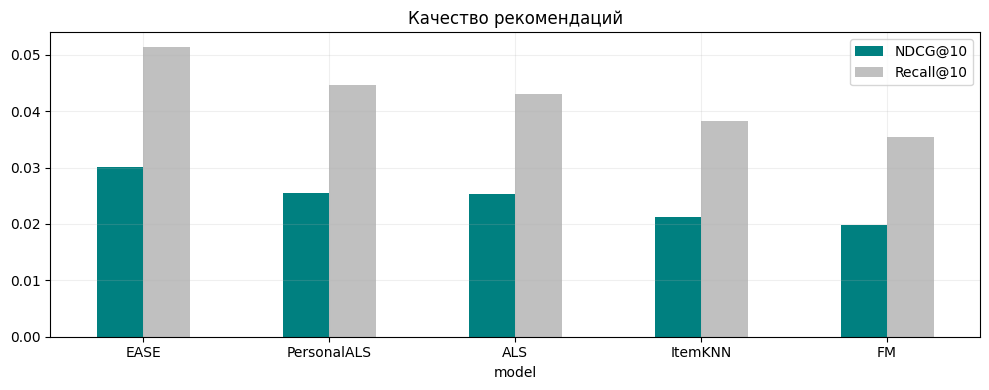

,parameters,seconds,NDCG@10,Recall@10
model,,,,
ALS,"{'rank': 24, 'penalty': 3.0}",11.420151,0.025336,0.043015
PersonalALS,"{'rank': 24, 'penalty': 3.0}",11.693212,0.025471,0.044554
PersonalALS_matched,"{'rank': 24, 'penalty': 3.0}",11.693212,0.025471,0.044554
FM,"{'factors': 24, 'reg': 1e-05, 'epochs': 11}",10.048488,0.019839,0.035436
FM_ID,"{'factors': 24, 'reg': 1e-05, 'epochs': 11, 'metadata': False}",6.134268,0.018518,0.031926


In [8]:
final = pd.DataFrame(report['final']).set_index('model')
main = final.loc[['ItemKNN', 'ALS', 'PersonalALS', 'EASE', 'FM']].sort_values('NDCG@10', ascending=False)
display(main)
main[['NDCG@10', 'Recall@10']].plot.bar(rot=0, color=['teal', 'silver'], title='Качество рекомендаций')
plt.tight_layout()
plt.show()
display(final.loc[['ALS', 'PersonalALS', 'PersonalALS_matched', 'FM', 'FM_ID']])

In [9]:
example = report['example']
print('Пример рекомендаций EASE для пользователя', example['user'])
display(metadata.iloc[example['items']][['title']].assign(rank=np.arange(1, 11)))

Пример рекомендаций EASE для пользователя 15


,title,rank
item_id,,
B0BCK6L7S5,"Donner Guitar Delay Pedal, Yellow Fall Analog Delay Guitar Effect Pedal Vintage Delay True Bypass",1
B0B95V41NR,D'Addario Guitar Cable - Guitar Patch Cable - Instrument Cable - Guitar Accessories - 1/4 Inch R...,2
B09857JRP2,GLS Audio Instrument Cable - Amp Cord for Bass & Electric Guitar - Straight to Right Angle 1/4 I...,3
B000T9L7W2,Behringer PSU-SB - General-Purpose DC 9V Power Adapter,4
B09PRKZ6FN,Donner 12 Inch Guitar Patch Cable Guitar Effect Pedal Cables Black 6 Pack,5
B0C61YVW2S,Behringer NOISE REDUCER NR300 Ultimate Noise Reduction Effects Pedal,6
B01M8K3VK1,BEHRINGER ULTRA CHORUS UC200 and BEHRINGER VINTAGE DELAY VD400 Bundle,7
B07MHL48V6,"Behringer VINTAGE DELAY VD400 Vintage Analog Delay Effects Pedal, White",8
B0BPLFP5P6,"D'Addario Accessories Guitar Tuner - Micro Headstock Tuner - Tuner for Acoustic Guitar, Electric...",9


# Выводы
Лучше всего получился EASE с регуляризацией 700: NDCG@10 равен 0.03001, Recall@10 равен 0.05141. ItemKNN уступил обеим ALS, хотя его обучение заметно быстрее.

Поправка на среднюю оценку пользователя дала небольшой прирост NDCG@10 с 0.02534 до 0.02547 при одинаковых настройках. Признаки FM повысили результат с 0.01852 до 0.01984, но эта модель все равно уступила остальным.

На test осталось 2835 пользователей. Отбор по активности и популярности исключил почти все поздние отзывы, поэтому результат нельзя переносить на весь каталог Amazon. Новые пользователи и товары не проверялись, а небольшой прирост PersonalALS может зависеть от разбиения.